# Auburn offensive line

Offensive line stats from `sql/Queries/sec_offensive_line.sql` (the line as a unit)
and `sql/Queries/sec_offensive_line_players.sql` (individual linemen).

Play-by-play data doesn't say who blocked whom, so blocking is graded **as a unit**:
line yards (each run's yards credited to the line: losses x1.2, 0-4 yards x1,
5-10 yards x0.5, 11+ x0), stuff rate, power success, sack rate and pressure rate.
The only **per-lineman** stat is penalties, which name the player in the play text.
Season and conference are set in each query's `params`.

In [1]:
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# project root = the folder containing .env (works from notebooks/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists())
load_dotenv(ROOT / ".env")

engine = create_engine(
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    f"@localhost:5432/{os.environ['POSTGRES_DB']}"
)

def read_query(name):
    # run a sql/Queries file; "%" is doubled because psycopg2 treats it as a
    # parameter marker (these queries use LIKE '%...')
    sql = (ROOT / "sql" / "Queries" / name).read_text()
    return pd.read_sql(sql.replace("%", "%%"), engine)

# chart colors: categorical slots 1-3, plus text and gray tones
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
SURFACE, INK, INK_2, MUTED = '#fcfcfb', '#0b0b0b', '#52514e', '#c9c7bf'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK_2,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlecolor': INK, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
})
TEAM = 'Auburn'

In [2]:
unit = read_query("sec_offensive_line.sql")
unit

,team,games,rushes,yards_per_rush,line_yards_per_rush,line_yards_rank,stuff_pct,stuff_rank,power_runs,power_pct,...,sack_rank,hurries,pressure_pct,pressure_rank,ol_penalties,ol_holding,ol_pre_snap,ol_penalties_per_game,penalty_rank,team_text_pct
0,Georgia,4,73,7.82,4.09,1,6.8,1,7,85.7,...,6,1,7.0,3,5,2,1,1.25,5,97.2
1,Tennessee,4,139,6.10,3.76,2,12.2,2,12,91.7,...,15,6,15.4,15,11,3,8,2.75,11,100.0
2,Mississippi State,4,113,6.13,3.66,3,15.0,9,7,100.0,...,6,5,9.7,4,11,7,2,2.75,11,100.0
3,South Carolina,4,120,7.16,3.66,3,15.0,9,12,75.0,...,5,9,12.8,9,6,2,4,1.50,7,100.0
4,Kentucky,4,117,6.70,3.63,5,12.8,5,8,62.5,...,13,6,12.9,10,4,2,2,1.00,1,98.0
5,Auburn,4,123,5.73,3.48,6,12.2,2,10,90.0,...,16,4,12.9,10,9,5,4,2.25,9,99.3
6,Alabama,4,117,6.13,3.35,7,17.1,13,6,83.3,...,12,6,11.5,6,4,0,3,1.00,1,75.2
7,LSU,4,128,5.07,3.23,8,14.8,7,7,71.4,...,9,10,14.9,13,12,5,4,3.00,14,100.0
8,Vanderbilt,4,129,4.50,3.20,9,12.4,4,19,78.9,...,4,16,16.2,16,13,6,6,3.25,15,98.5
9,Ole Miss,4,103,4.58,3.17,10,14.6,6,14,78.6,...,1,15,12.3,8,4,3,0,1.00,1,97.9


In [3]:
ol = read_query("sec_offensive_line_players.sql")
ol

,player,team,pos,jersey,class_year,height_in,weight_lb,penalties,holding,pre_snap,other,foul_types,penalty_yards,yards_wiped_out,tds_wiped_out,drive_killers,team_games,team_ol_snaps,penalties_per_100_snaps,yards_cost_per_game
0,Miles McVay,Mississippi State,OL,58,3,78,335,4,2,1,1,"Face Mask, False Start, Holding",40,9,0,0,4,285,1.40,12.3
1,Jordan Seaton,LSU,OT,77,3,77,307,4,0,2,2,"False Start, Personal Foul",40,0,0,0,4,315,1.27,10.0
2,Orion Irving,Vanderbilt,OL,58,4,78,310,3,2,0,1,"Holding, Ineligible Downfield on Pass",25,23,0,1,4,264,1.14,12.0
3,Curtis Peagler,Missouri,OL,77,4,76,335,3,3,0,0,Holding,30,6,0,0,4,271,1.11,9.0
4,DJ Chester,Mississippi State,OL,78,3,78,315,3,1,1,1,"False Start, Holding, Personal Foul",26,0,0,0,4,285,1.05,6.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72,Jesse Perry,Tennessee,OL,72,2,78,320,1,0,1,0,False Start,5,0,0,0,4,283,0.35,1.3
73,Dontrell Glover,Georgia,OL,63,2,75,320,1,0,0,1,Face Mask,5,0,0,0,4,235,0.43,1.3
74,Nolan Hay,South Carolina,OL,62,4,75,328,1,0,1,0,False Start,5,0,0,0,4,291,0.34,1.3
75,Jayvin James,Alabama,OL,54,4,77,317,1,0,1,0,False Start,5,0,0,0,4,269,0.37,1.3


## Auburn's linemen: penalties by type

Only linemen with at least one accepted penalty appear (the data has no snap
counts, so a lineman with no penalties can't be told apart from one who didn't
play). The label at the end of each bar is the yards the penalties cost: penalty
yards plus any gain that was called back.

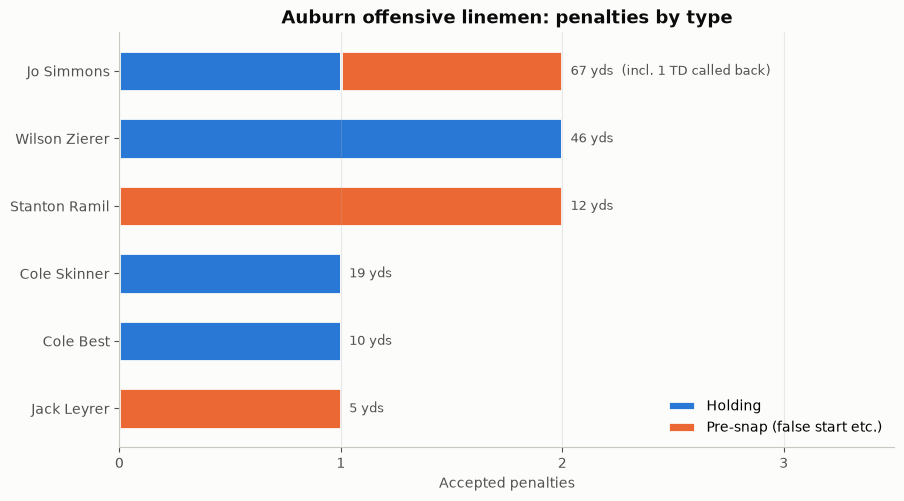

In [4]:
aub = ol[ol['team'] == TEAM].copy()
aub['yards_cost'] = aub['penalty_yards'] + aub['yards_wiped_out']
aub = aub.sort_values(['penalties', 'yards_cost'])

TYPES = [('holding', 'Holding', BLUE), ('pre_snap', 'Pre-snap (false start etc.)', ORANGE), ('other', 'Other', AQUA)]

fig, ax = plt.subplots(figsize=(10, 0.6 * len(aub) + 1.8))
left = pd.Series(0, index=aub.index)
for col, label, color in TYPES:
    if aub[col].sum() == 0:
        continue   # no penalties of this type: leave it out of the legend
    ax.barh(aub['player'], aub[col], left=left, color=color, height=0.6,
            edgecolor=SURFACE, linewidth=2, label=label)
    left += aub[col]

for (_, r), end in zip(aub.iterrows(), left):
    note = f"{r['yards_cost']} yds"
    if r['tds_wiped_out']:
        note += f"  (incl. {r['tds_wiped_out']} TD called back)"
    ax.annotate(note, (end, r['player']), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=9, color=INK_2)

ax.set_xlabel('Accepted penalties')
ax.xaxis.get_major_locator().set_params(integer=True)
ax.set_xlim(0, left.max() + 1.5)
ax.set_title(f'{TEAM} offensive linemen: penalties by type')
ax.grid(axis='x', alpha=0.25)
ax.legend(loc='lower right', frameon=False)
plt.show()

## SEC linemen: the costliest penalties

The 20 SEC linemen whose penalties cost the most yards: penalty yards plus gains
called back (e.g. a long run or touchdown erased by holding). Auburn's linemen
are marked in the labels.

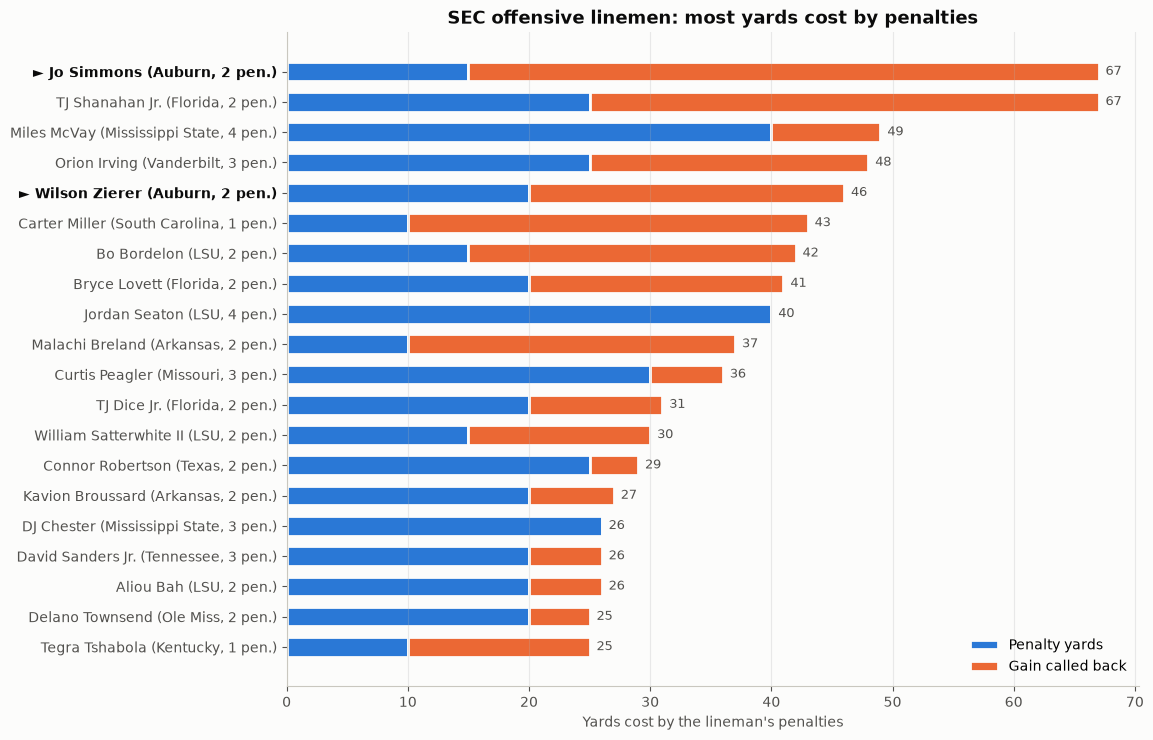

In [5]:
ol['yards_cost'] = ol['penalty_yards'] + ol['yards_wiped_out']
top = ol.nlargest(20, ['yards_cost', 'penalties']).iloc[::-1]
labels = [f"{'► ' if t == TEAM else ''}{p} ({t}, {n} pen.)"
          for p, t, n in zip(top['player'], top['team'], top['penalties'])]

fig, ax = plt.subplots(figsize=(11, 8.5))
ax.barh(labels, top['penalty_yards'], color=BLUE, height=0.65,
        edgecolor=SURFACE, linewidth=2, label='Penalty yards')
ax.barh(labels, top['yards_wiped_out'], left=top['penalty_yards'], color=ORANGE, height=0.65,
        edgecolor=SURFACE, linewidth=2, label='Gain called back')
for lbl, total in zip(labels, top['yards_cost']):
    ax.annotate(f'{total}', (total, lbl), xytext=(5, 0), textcoords='offset points',
                va='center', fontsize=9, color=INK_2)
for tick, t in zip(ax.get_yticklabels(), top['team']):
    if t == TEAM:
        tick.set_fontweight('bold'); tick.set_color(INK)

ax.set_xlabel('Yards cost by the lineman\'s penalties')
ax.set_title('SEC offensive linemen: most yards cost by penalties')
ax.grid(axis='x', alpha=0.25)
ax.legend(loc='lower right', frameon=False)
plt.show()

## Auburn's line vs. the rest of the SEC

One panel per stat, teams sorted best to worst, Auburn in blue. The dashed line
is the SEC average.

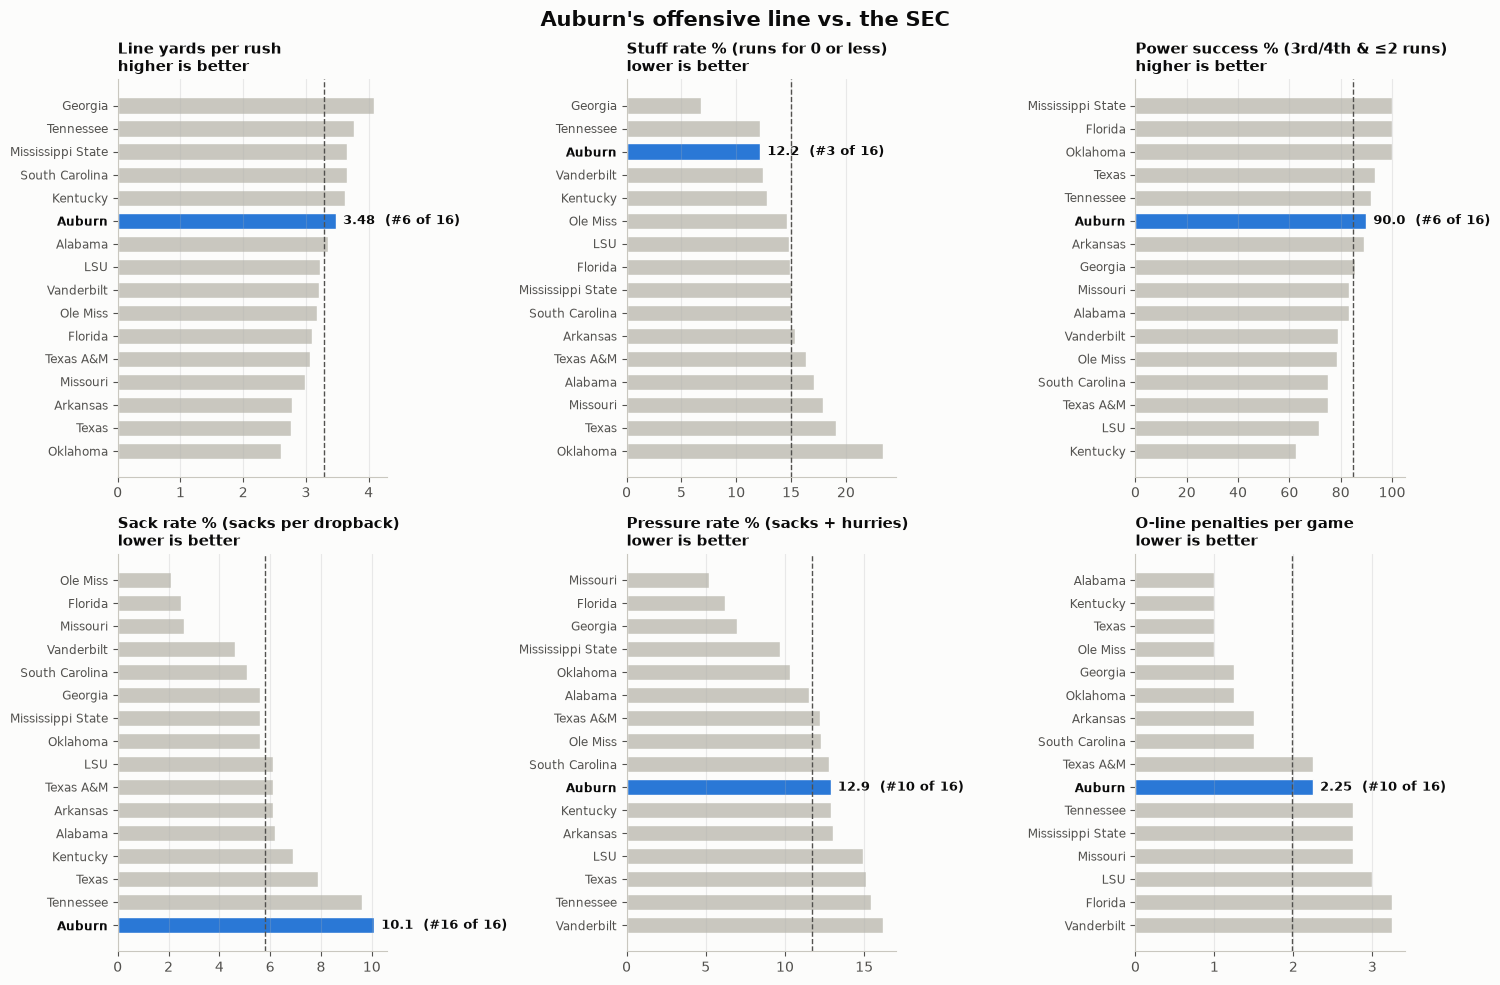

In [6]:
METRICS = [  # column, title, higher_is_better, format
    ('line_yards_per_rush', 'Line yards per rush', True,  '{:.2f}'),
    ('stuff_pct',           'Stuff rate % (runs for 0 or less)', False, '{:.1f}'),
    ('power_pct',           'Power success % (3rd/4th & ≤2 runs)', True, '{:.1f}'),
    ('sack_pct',            'Sack rate % (sacks per dropback)', False, '{:.1f}'),
    ('pressure_pct',        'Pressure rate % (sacks + hurries)', False, '{:.1f}'),
    ('ol_penalties_per_game', 'O-line penalties per game', False, '{:.2f}'),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (col, title, higher_better, fmt) in zip(axes.flat, METRICS):
    d = unit.sort_values(col, ascending=not higher_better)[::-1]   # best at the top
    colors = [BLUE if t == TEAM else MUTED for t in d['team']]
    ax.barh(d['team'], d[col], color=colors, height=0.7, edgecolor=SURFACE, linewidth=1)
    ax.axvline(unit[col].mean(), color=INK_2, lw=1, ls='--')

    rank = list(d['team'][::-1]).index(TEAM) + 1
    val = d.loc[d['team'] == TEAM, col].iloc[0]
    ax.annotate(f'{fmt.format(val)}  (#{rank} of {len(d)})', (val, TEAM), xytext=(5, 0),
                textcoords='offset points', va='center', fontsize=9, color=INK, weight='bold')
    for tick in ax.get_yticklabels():
        if tick.get_text() == TEAM:
            tick.set_fontweight('bold'); tick.set_color(INK)
    ax.tick_params(axis='y', labelsize=8.5)
    ax.set_title(f"{title}\n{'higher' if higher_better else 'lower'} is better",
                 fontsize=10.5, loc='left')
    ax.grid(axis='x', alpha=0.25)

fig.suptitle(f"{TEAM}'s offensive line vs. the SEC", fontsize=15, fontweight='bold', color=INK)
fig.tight_layout()
plt.show()

In [7]:
# Auburn's run blocking by side of the line vs. the SEC average
sides = ['left', 'middle', 'right']
cmp = pd.DataFrame({
    TEAM: [unit.loc[unit['team'] == TEAM, f'line_yards_{s}'].iloc[0] for s in sides],
    'SEC average': [unit[f'line_yards_{s}'].mean() for s in sides],
    f'{TEAM} runs': [unit.loc[unit['team'] == TEAM, f'runs_{s}'].iloc[0] for s in sides],
    f'{TEAM} stuff %': [unit.loc[unit['team'] == TEAM, f'stuff_pct_{s}'].iloc[0] for s in sides],
    'SEC stuff %': [unit[f'stuff_pct_{s}'].mean() for s in sides],
}, index=[f'Runs {s}' for s in sides]).round(2)
cmp

,Auburn,SEC average,Auburn runs,Auburn stuff %,SEC stuff %
Runs left,3.88,3.57,12,0.0,14.34
Runs middle,3.32,3.11,83,13.3,14.59
Runs right,3.78,3.44,28,14.3,17.04


## Run direction: Auburn vs. the SEC

Run direction comes from the play text ("rush left / middle / right"), so it's
the side the ball carrier went, not necessarily the designed gap. QB scrambles
are included.

**How often vs. how well:** each panel is one direction. Across: the share of
the team's runs that went that way. Up: line yards per rush that way. Dot size =
number of runs, so small dots are small samples. Dashed lines are SEC averages.

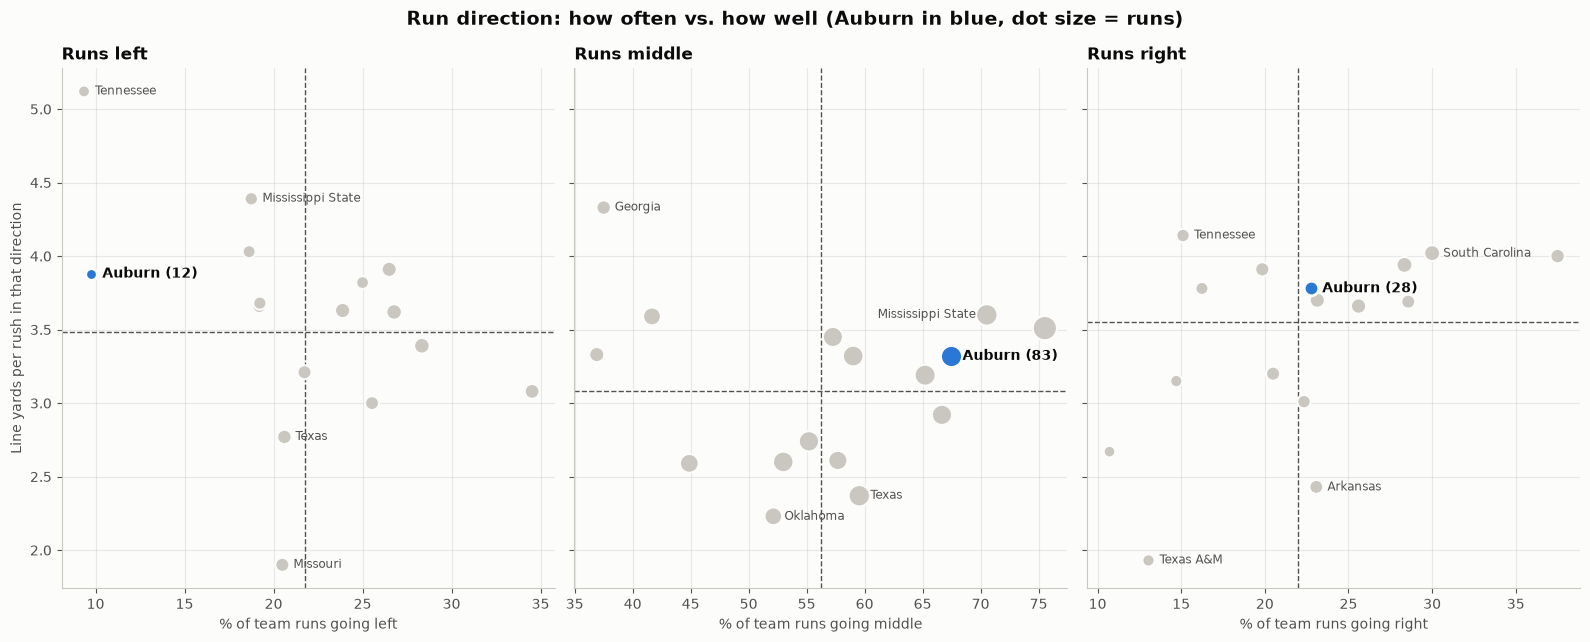

In [8]:
from matplotlib.transforms import Bbox

AUB_LABEL = dict(fontsize=10, color=INK, weight='bold')
OTHER_LABEL = dict(fontsize=8.5, color=INK_2)

def place_labels(ax, items, dot_px=7):
    # items: list of (x, y, text, annotate kwargs), most important first.
    # Tries spots around each dot and keeps the first that stays inside the
    # axes without overlapping a placed label or any dot; failing that, it
    # tries spots further out with a leader line. Call after the axes limits
    # and figure layout are final.
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    taken = [Bbox.from_bounds(px - dot_px, py - dot_px, 2 * dot_px, 2 * dot_px)
             for px, py in (ax.transData.transform((x, y)) for x, y, _, _ in items)]
    near = [(8, 0, 'left', 'center'), (-8, 0, 'right', 'center'), (0, 9, 'center', 'bottom'),
            (0, -9, 'center', 'top'), (7, 8, 'left', 'bottom'), (7, -8, 'left', 'top'),
            (-7, 8, 'right', 'bottom'), (-7, -8, 'right', 'top')]
    far = [(24, 20, 'left', 'bottom'), (24, -20, 'left', 'top'),
           (-24, 20, 'right', 'bottom'), (-24, -20, 'right', 'top')]
    for x, y, text, kw in items:
        for dx, dy, ha, va in near + far:
            line = dict(arrowstyle='-', color=MUTED, lw=0.8) if (dx, dy, ha, va) in far else None
            a = ax.annotate(text, (x, y), xytext=(dx, dy), textcoords='offset points',
                            ha=ha, va=va, arrowprops=line, **kw)
            box = a.get_window_extent(renderer)
            inside = ax.bbox.contains(box.x0, box.y0) and ax.bbox.contains(box.x1, box.y1)
            if inside and not any(box.overlaps(t) for t in taken):
                taken.append(box)
                break
            a.remove()
        else:   # no free spot: fall back to the right of the dot
            a = ax.annotate(text, (x, y), xytext=(8, 0), textcoords='offset points', va='center', **kw)
            taken.append(a.get_window_extent(renderer))

SIDES = ['left', 'middle', 'right']
d = unit[['team'] + [f'runs_{s}' for s in SIDES] + [f'line_yards_{s}' for s in SIDES]
         + [f'stuff_pct_{s}' for s in SIDES]].copy()
d['dir_runs'] = d[[f'runs_{s}' for s in SIDES]].sum(axis=1)
for s in SIDES:
    d[f'share_{s}'] = d[f'runs_{s}'] / d['dir_runs'] * 100
is_aub = d['team'] == TEAM

fig, axes = plt.subplots(1, 3, figsize=(16, 6.5), sharey=True)
for ax, s in zip(axes, SIDES):
    x, y, n = d[f'share_{s}'], d[f'line_yards_{s}'], d[f'runs_{s}']
    size = 40 + n * 2.5      # minimum size so small samples stay visible
    ax.scatter(x[~is_aub], y[~is_aub], s=size[~is_aub], c=MUTED, edgecolors=SURFACE, linewidths=1.5, zorder=2)
    ax.scatter(x[is_aub], y[is_aub], s=size[is_aub], c=BLUE, edgecolors=SURFACE, linewidths=2, zorder=3)
    ax.axvline(x.mean(), color=INK_2, lw=1, ls='--', zorder=1)
    ax.axhline((y * n).sum() / n.sum(), color=INK_2, lw=1, ls='--', zorder=1)
    ax.set_title(f'Runs {s}', loc='left', fontsize=12)
    ax.set_xlabel(f'% of team runs going {s}')
    ax.grid(alpha=0.25)
axes[0].set_ylabel('Line yards per rush in that direction')
fig.suptitle(f'Run direction: how often vs. how well ({TEAM} in blue, dot size = runs)',
             fontsize=14, fontweight='bold', color=INK)
fig.tight_layout()

# label Auburn (with its run count) plus the two best and two worst in each direction
for ax, s in zip(axes, SIDES):
    show = set(d.nlargest(2, f'line_yards_{s}')['team']) | set(d.nsmallest(2, f'line_yards_{s}')['team'])
    rows = pd.concat([d[is_aub], d[~is_aub & d['team'].isin(show)]])
    place_labels(ax, [(r[f'share_{s}'], r[f'line_yards_{s}'],
                       f"{r['team']} ({r[f'runs_{s}']})" if r['team'] == TEAM else r['team'],
                       AUB_LABEL if r['team'] == TEAM else OTHER_LABEL)
                      for _, r in rows.iterrows()])
plt.show()

**Which side of the line is stronger:** line yards running left vs. running
right. Teams above the diagonal block better going right; below it, going left.
Dashed lines are SEC averages.

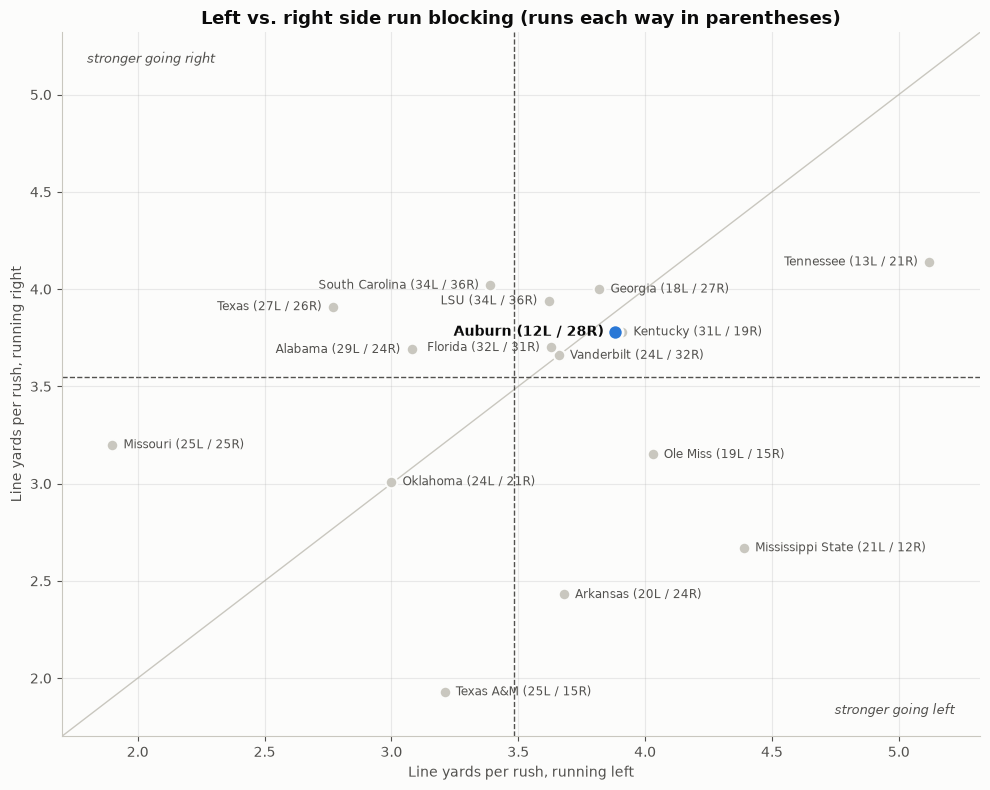

In [9]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(d.loc[~is_aub, 'line_yards_left'], d.loc[~is_aub, 'line_yards_right'], s=70, c=MUTED,
           edgecolors=SURFACE, linewidths=1.5, zorder=2)
ax.scatter(d.loc[is_aub, 'line_yards_left'], d.loc[is_aub, 'line_yards_right'], s=120, c=BLUE,
           edgecolors=SURFACE, linewidths=2, zorder=3)

lo = min(d['line_yards_left'].min(), d['line_yards_right'].min()) - 0.2
hi = max(d['line_yards_left'].max(), d['line_yards_right'].max()) + 0.2
ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1, zorder=1)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.axvline((d['line_yards_left'] * d['runs_left']).sum() / d['runs_left'].sum(), color=INK_2, lw=1, ls='--', zorder=1)
ax.axhline((d['line_yards_right'] * d['runs_right']).sum() / d['runs_right'].sum(), color=INK_2, lw=1, ls='--', zorder=1)
ax.annotate('stronger going right', (lo + 0.1, hi - 0.1), ha='left', va='top', fontsize=9, color=INK_2, style='italic')
ax.annotate('stronger going left', (hi - 0.1, lo + 0.1), ha='right', va='bottom', fontsize=9, color=INK_2, style='italic')

ax.set_xlabel('Line yards per rush, running left')
ax.set_ylabel('Line yards per rush, running right')
ax.set_title('Left vs. right side run blocking (runs each way in parentheses)')
ax.grid(alpha=0.25)
fig.tight_layout()

rows = pd.concat([d[is_aub], d[~is_aub]])   # Auburn's label gets first pick of spots
place_labels(ax, [(r['line_yards_left'], r['line_yards_right'], f"{r['team']} ({r['runs_left']}L / {r['runs_right']}R)",
                   AUB_LABEL if r['team'] == TEAM else OTHER_LABEL)
                  for _, r in rows.iterrows()])
plt.show()

In [10]:
# the numbers behind the charts, Auburn first
cols = ['team', 'dir_runs'] + [f'{m}_{s}' for s in SIDES for m in ('runs', 'share', 'line_yards', 'stuff_pct')]
d[cols].assign(_aub=~is_aub).sort_values(['_aub', 'team']).drop(columns='_aub').round(1)

,team,dir_runs,runs_left,share_left,line_yards_left,stuff_pct_left,runs_middle,share_middle,line_yards_middle,stuff_pct_middle,runs_right,share_right,line_yards_right,stuff_pct_right
5,Auburn,123,12,9.8,3.9,0.0,83,67.5,3.3,13.3,28,22.8,3.8,14.3
6,Alabama,84,29,34.5,3.1,24.1,31,36.9,3.3,12.9,24,28.6,3.7,20.8
13,Arkansas,104,20,19.2,3.7,10.0,60,57.7,2.6,15.0,24,23.1,2.4,20.8
10,Florida,134,32,23.9,3.6,18.8,71,53.0,2.6,14.1,31,23.1,3.7,12.9
0,Georgia,72,18,25.0,3.8,11.1,27,37.5,4.3,3.7,27,37.5,4.0,7.4
4,Kentucky,117,31,26.5,3.9,16.1,67,57.3,3.4,7.5,19,16.2,3.8,26.3
7,LSU,127,34,26.8,3.6,11.8,57,44.9,2.6,17.5,36,28.3,3.9,11.1
2,Mississippi State,112,21,18.8,4.4,9.5,79,70.5,3.6,15.2,12,10.7,2.7,25.0
12,Missouri,122,25,20.5,1.9,32.0,72,59.0,3.3,15.3,25,20.5,3.2,12.0
15,Oklahoma,94,24,25.5,3.0,25.0,49,52.1,2.2,26.5,21,22.3,3.0,14.3
